# MSIS822 | Detection of AI-Generated Arabic Text
## مشروع كشف النص العربي المولد بالذكاء الاصطناعي

**الطالب: عمران | التنفيذ الحالي: المرحلة الأولى والثانية**

هدفي في هذا الجزء هو فهم بيانات الملخصات العربية، وتجهيز تصنيف النص البشري والمولد،
ثم تطبيق معالجة عربية ومقارنة الخصائص اللغوية للفئتين.

أقرأ شرح الخطوة، ثم أشغل خلية الكود، ثم أراجع الملاحظة التي تليها لفهم الناتج.
للتشغيل الكامل أستخدم **Runtime > Run all**. CPU عادي يكفي لهذا الجزء.

| المرحلة | الحالة |
|---|---|
| 1. إعداد المشروع والحصول على البيانات | مكتملة في هذا الدفتر |
| 2. المعالجة العربية والتحليل الاستكشافي | مكتملة في هذا الدفتر |
| 3. هندسة الخصائص | خطة مستقبلية فقط |
| 4. بناء النماذج والتقييم | خطة مستقبلية فقط |
| 5. التفسير والتقرير والعرض | خطة مستقبلية فقط |

**المصدر:** [بيانات KFUPM-JRCAI](https://huggingface.co/datasets/KFUPM-JRCAI/arabic-generated-abstracts).
المتطلبات مستندة إلى تعليمات MSIS822. الأرقام والرسوم في الخلايا ناتجة عن التشغيل على البيانات.


## Phase 1 - Project Setup & Data Acquisition
### 1.1 | تثبيت المكتبات وبناء مجلدات المشروع
نستخدم `datasets` للتحميل المباشر من Hugging Face، وNLTK لقائمة كلمات الوقف العربية
وISRI. نحفظ البيانات الأصلية منفصلة عن المعالجة، ونحفظ الرسوم والجداول تلقائيًا.
لا يتطلب مصدر البيانات العام رمز Hugging Face أو حسابًا مدفوعًا.


In [1]:
# ملاحظة الطالب: تجهيز المكتبات
# Colab/Jupyter: install before importing packages. CPU is sufficient.
%pip -q install "datasets>=3.6,<6" "nltk>=3.9,<4" "matplotlib>=3.9,<4" "pandas>=2.2,<4" "wordcloud>=1.9,<2" "arabic-reshaper>=3,<4" "python-bidi>=0.6,<1" "pyarrow>=19"


Local verification: dependencies installed in an isolated workspace directory. Run this cell normally in Colab.


### ملاحظتي على خطوة تجهيز المكتبات

**ماذا فعلت؟** أثبت المكتبات التي يحتاجها المشروع قبل استيرادها. هذه خطوة إعداد للبيئة وليست تحليلًا للبيانات.

**كيف أقرأ الناتج؟** رسائل التثبيت عادية. أنتقل للخلية التالية بعد انتهائها دون خطأ. التشغيل على CPU يكفي لهاتين المرحلتين.

**لماذا هذه الخطوة؟** استخدمت datasets للتحميل وNLTK للمعالجة العربية، وMatplotlib وWordCloud للعرض.


In [2]:
# ملاحظة الطالب: إعداد المشروع
from pathlib import Path
from collections import Counter
from functools import lru_cache
import hashlib, json, re, sys, unicodedata, platform, shutil, os, tempfile
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from datasets import load_dataset
import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer
from wordcloud import WordCloud
import arabic_reshaper
from bidi.algorithm import get_display

# ملاحظة: المسار الرئيسي: كل الملفات التي يولدها التشغيل توضع تحته.
PROJECT = Path.cwd() / 'MSIS822_Arabic_AI_Phases_1_2'
for name in ['data/raw', 'data/processed', 'data/external', 'notebooks', 'src',
             'reports/figures', 'reports/tables', 'docs']:
    (PROJECT / name).mkdir(parents=True, exist_ok=True)
FIGURES, TABLES = PROJECT/'reports/figures', PROJECT/'reports/tables'
SEED = 822
DATASET_ID = 'KFUPM-JRCAI/arabic-generated-abstracts'
# Fixed source revision ensures repeatable dataset contents.
# ملاحظة: نسخة ثابتة من المصدر حتى لا تتغير النتائج بسبب تحديث البيانات.
REVISION = '584e43a346914a4cb1a51f9679f903284b65c36e'
METHODS = ['by_polishing', 'from_title', 'from_title_and_content']
TEXT_COLUMNS = ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract',
                'llama_generated_abstract', 'openai_generated_abstract']
LABELS = ['Human', 'AI']
COLORS = {'Human': '#197887', 'AI': '#c26a3c'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
# ملاحظة: دالة صغيرة تحفظ الجدول بصيغة تدعم العربية في Excel.
def save_table(df, name, index=True):
    df.to_csv(TABLES/f'{name}.csv', index=index, encoding='utf-8-sig')
# ملاحظة: أحفظ الرسم قبل عرضه حتى يكون جاهزًا للتسليم.
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES/f'{name}.png', dpi=170, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def ar(text):
    return get_display(arabic_reshaper.reshape(str(text)))
print('Project folder:', PROJECT)
print('Python:', platform.python_version())


Project folder: C:\Users\omran\AppData\Local\Temp\m822-run\MSIS822_Arabic_AI_Phases_1_2
Python: 3.12.14


### ملاحظتي على خطوة إعداد المشروع

**ماذا فعلت؟** أحدد مصدر البيانات وبذرة العشوائية ومسارات الحفظ، ثم أجهز دوال حفظ الرسوم والجداول.

**كيف أقرأ الناتج؟** PROJECT هو مجلد النتائج داخل جلسة التشغيل. الرقم 822 يجعل التقسيم قابلًا للتكرار، وREVISION يثبت نسخة البيانات.

**لماذا هذه الخطوة؟** فصلت البيانات الأصلية عن المعالجة حتى أستطيع الرجوع إلى النص كما نزل من المصدر.


### 1.2 | تحميل البيانات وفهم بنيتها - Task 1.2
أسماء `by_polishing` و`from_title` و`from_title_and_content` هي **طرق توليد**؛
ليست مجموعات تدريب واختبار. لا نفترض وجود عمود `label` جاهز.
كل صف أصلي يتضمن ملخصًا بشريًا وأربعة أعمدة لتوليد النماذج.
الأعداد التالية تُستخرج من النسخة المثبتة، ثم نحفظ كل جزء كما هو.


In [3]:
# ملاحظة الطالب: تحميل البيانات وفحصها
# A short Windows cache path avoids the platform's filename-length limit.
HF_CACHE = Path(tempfile.gettempdir())/'m822-hf' if os.name=='nt' else PROJECT/'data/external/hf_cache'
# ملاحظة: تحميل البيانات العامة بالمكتبة المطلوبة في تعليمات المشروع.
dataset = load_dataset(DATASET_ID, revision=REVISION, cache_dir=str(HF_CACHE))
print(dataset)
schema_rows, quality_rows, frames = [], [], []
# ملاحظة: أكرر الفحص نفسه على طرق التوليد الثلاث دون خلطها بالتقسيم الإحصائي.
for method in METHODS:
    part = dataset[method].to_pandas()
    assert set(TEXT_COLUMNS).issubset(part.columns), (method, list(part.columns))
    # ملاحظة: أحفظ البيانات الأصلية قبل أي تحويل أو تنظيف.
    part.to_parquet(PROJECT/f'data/raw/{method}.parquet', index=False)
    for col in TEXT_COLUMNS:
        values = part[col]
        schema_rows.append({'method': method, 'column': col, 'dtype': str(values.dtype)})
        # ملاحظة: كل سطر في تقرير الجودة يخص عمودًا نصيًا داخل إحدى طرق التوليد.
        quality_rows.append({
            'method': method, 'column': col, 'rows': len(part),
            'missing': int(values.isna().sum()),
            'blank_strings': int(values.map(lambda x: isinstance(x,str) and not x.strip()).sum()),
            'non_string_non_null': int(values.map(lambda x: not isinstance(x,str) and pd.notna(x)).sum()),
            'exact_duplicate_non_null_cells': int(values.dropna().duplicated().sum()),
            'exact_duplicate_wide_rows': int(part.duplicated().sum())})
    part['generation_method'] = method
    part['source_row'] = [f'{method}:{i}' for i in range(len(part))]
    frames.append(part)
wide = pd.concat(frames, ignore_index=True)
schema = pd.DataFrame(schema_rows)
quality = pd.DataFrame(quality_rows)
display(wide.groupby('generation_method').size().rename('source_rows').to_frame())
display(schema)
display(quality)
display(wide[TEXT_COLUMNS].head(2))
save_table(schema, 'phase1_schema', False)
save_table(quality, 'phase1_raw_quality', False)
print('Total source rows:', len(wide), '| Text slots before cleaning:', len(wide)*5)


DatasetDict({
    by_polishing: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2851
    })
    from_title: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2963
    })
    from_title_and_content: Dataset({
        features: ['original_abstract', 'allam_generated_abstract', 'jais_generated_abstract', 'llama_generated_abstract', 'openai_generated_abstract'],
        num_rows: 2574
    })
})
Total source rows: 8388 | Text slots before cleaning: 41940


Generating from_title_and_content split: 100%|##########| 2574/2574 [00:00<00:00, 113079.36 examples/s]


,source_rows
generation_method,
by_polishing,2851
from_title,2963
from_title_and_content,2574


,method,column,dtype
0,by_polishing,original_abstract,str
1,by_polishing,allam_generated_abstract,str
2,by_polishing,jais_generated_abstract,str
3,by_polishing,llama_generated_abstract,str
4,by_polishing,openai_generated_abstract,str
5,from_title,original_abstract,str
6,from_title,allam_generated_abstract,str
7,from_title,jais_generated_abstract,str
8,from_title,llama_generated_abstract,str
9,from_title,openai_generated_abstract,str


,method,column,rows,missing,blank_strings,non_string_non_null,exact_duplicate_non_null_cells,exact_duplicate_wide_rows
0,by_polishing,original_abstract,2851,0,0,0,0,0
1,by_polishing,allam_generated_abstract,2851,0,0,0,0,0
2,by_polishing,jais_generated_abstract,2851,0,0,0,0,0
3,by_polishing,llama_generated_abstract,2851,0,0,0,0,0
4,by_polishing,openai_generated_abstract,2851,0,0,0,0,0
5,from_title,original_abstract,2963,0,0,0,0,0
6,from_title,allam_generated_abstract,2963,0,0,0,0,0
7,from_title,jais_generated_abstract,2963,0,0,0,0,0
8,from_title,llama_generated_abstract,2963,0,0,0,0,0
9,from_title,openai_generated_abstract,2963,0,0,0,0,0


,original_abstract,allam_generated_abstract,jais_generated_abstract,llama_generated_abstract,openai_generated_abstract
0,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خ...,يتناول هذا البحث موضوع التعليم بين النساء الأن...,تدرس هذه الدراسة دور المرأة في التعليم في الأن...,يُقدم هذا البحث دراسة شاملة حول حالة التعليم ع...,صور نظام التعليم عند المرأة الأندلسية تستند إل...
1,يعد العامل الثقافي احد ابرز الاسباب التي يعزى ...,يتناول هذا البحث دراسة انهيار دولة الموحدين من...,كان العامل الثقافي من بين الأسباب الرئيسية الت...,يعد العامل الثقافي أحد أبرز الأسباب التي يعزى ...,انهيار دولة الموحدين يعود بشكل كبير للعوامل ال...


### ملاحظتي على خطوة تحميل البيانات وفحصها

**ماذا فعلت؟** أحمل الأجزاء الثلاثة وأعرض أعمدتها وأنواعها وجودتها، وأحفظ نسخة أصلية لكل جزء.

**كيف أقرأ الناتج؟** المجموع 8,388 صفًا أصليًا؛ كل صف يضم خمسة أعمدة نصية. أسماء الأجزاء تمثل طرق توليد وليست train/test.

**لماذا هذه الخطوة؟** فحصت missing والقيم الفارغة والأنواع والتكرار قبل أي تنظيف حتى لا تختفي المشكلة من التقرير.


### 1.3 | إنشاء التصنيف Human / AI - Task 1.3
نحوّل البيانات من الشكل العريض إلى صف لكل نص: `original_abstract → Human (0)`،
وأعمدة النماذج الأربعة `→ AI (1)`، مع الاحتفاظ بطريقة التوليد والمصدر.
نرصد النقص قبل الحذف؛ لا نستبدل القيم الناقصة بكلمة `nan` ولا بنص فارغ.
تكرار الملخص البشري عبر طرق التوليد لا يعني وجود ملخصات بشرية مستقلة جديدة.


In [4]:
# ملاحظة الطالب: تجهيز النص والتصنيف
# ملاحظة: توحيد Unicode والمسافات لمقارنة النصوص الكاملة بشكل منصف.
def canonical(text):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', text)).strip()

# Stateless Arabic normalization is also used for integrity grouping.
DIACRITICS = re.compile(r'[\u0610-\u061a\u064b-\u065f\u0670\u06d6-\u06ed]')
ARABIC_LETTERS = re.compile(r'[\u0621-\u063a\u0641-\u064a]+')
# ملاحظة: نسخة عربية مبسطة؛ النص الأصلي يبقى محفوظًا للتحليل الأسلوبي.
def normalize_arabic(text):
    if not isinstance(text, str):
        return ''
    text = unicodedata.normalize('NFKC', text)
    text = DIACRITICS.sub('', text).replace('ـ', '')
    # Preserve standalone hamza, waw/ya hamza and taa marbuta to limit semantic loss.
    text = re.sub('[أإآٱ]', 'ا', text).replace('ى', 'ي')
    # Separate punctuation/digits/foreign runs instead of merging adjacent words.
    return ' '.join(ARABIC_LETTERS.findall(text))

wide['source_group'] = wide.apply(
    lambda r: hashlib.sha256(canonical(r['original_abstract']).encode()).hexdigest()
    if isinstance(r['original_abstract'], str) and r['original_abstract'].strip()
    else 'missing-original:'+r['source_row'], axis=1)
# ملاحظة: التحويل من خمسة أعمدة نصية إلى عمود نص واحد مع عمود يبين المصدر.
long = wide.melt(id_vars=['source_row','source_group','generation_method'],
                 value_vars=TEXT_COLUMNS, var_name='source_column', value_name='text_raw')
# ملاحظة: التصنيف يأتي من عمود المصدر، ولا نستنتجه من محتوى النص.
long['label'] = long['source_column'].ne('original_abstract').astype(int)
long['class_name'] = long['label'].map({0:'Human',1:'AI'})
long['generator'] = long['source_column'].str.replace('_generated_abstract','',regex=False)
long.loc[long['label'].eq(0), 'generator'] = 'human'
long['is_valid_string'] = long['text_raw'].map(lambda x: isinstance(x,str) and bool(x.strip()))
invalid = long.loc[~long['is_valid_string']].copy()
valid = long.loc[long['is_valid_string']].copy()
valid['text_key'] = valid['text_raw'].map(canonical)
valid['text_normalized'] = valid['text_raw'].map(normalize_arabic)
no_arabic = valid.loc[valid['text_normalized'].eq('')].copy()
valid = valid.loc[valid['text_normalized'].ne('')].copy()
# ملاحظة: أبحث عن النص المطبع الذي ظهر بتصنيفين متعارضين لعزله.
conflict_keys = valid.groupby('text_normalized')['label'].nunique()
conflict_keys = set(conflict_keys[conflict_keys.gt(1)].index)
conflicts = valid.loc[valid['text_normalized'].isin(conflict_keys)].copy()
valid = valid.loc[~valid['text_normalized'].isin(conflict_keys)].copy()
display(pd.crosstab(long['generation_method'], long['class_name']).reindex(columns=LABELS))
print('Invalid/empty text slots:',len(invalid),'| No Arabic letters:',len(no_arabic))
print('Rows with contradictory labels after fixed normalization:',len(conflicts))
print('Repeated exact texts (beyond first):',int(valid.duplicated('text_key').sum()))
for name, frame in [('invalid_slots',invalid), ('no_arabic',no_arabic), ('label_conflicts',conflicts)]:
    save_table(frame, 'phase1_'+name, False)


Invalid/empty text slots: 0 | No Arabic letters: 4
Rows with contradictory labels after fixed normalization: 117
Repeated exact texts (beyond first): 5341


class_name,Human,AI
generation_method,,
by_polishing,2851,11404
from_title,2963,11852
from_title_and_content,2574,10296


### ملاحظتي على خطوة تجهيز النص والتصنيف

**ماذا فعلت؟** أحول الأعمدة إلى صف مستقل لكل نص، وأضيف label ومعلومات المصدر، ثم أعزل النصوص غير الصالحة والمتعارضة.

**كيف أقرأ الناتج؟** Human=0 وAI=1. قبل التنظيف هناك 41,940 خانة نص. عزلت 4 نصوص بلا حروف عربية و117 وقوعًا متعارض التصنيف بعد التطبيع.

**لماذا هذه الخطوة؟** التعارض يعني أن النص المطبع نفسه ظهر تحت الفئتين؛ عزلته للمراجعة بدل تخمين تصنيفه.


### 1.4 | معالجة التكرارات وحفظ مصدر كل نص
نحذف تكرار النص الكامل داخل التصنيف، مع تجميع معلومات مصدره بدل فقدها.
النص نفسه ذو تصنيفين متعارضين بعد التطبيع يُعزل للمراجعة ولا تُخمن تسميته.
نربط الملخص البشري وجميع نسخه المولدة في مجموعة واحدة، ونربط المجموعات إذا تشاركت نصًا
بعد التطبيع. هذا يقلل تسرب نسخ نفس البحث إلى مجموعات مختلفة لاحقًا.


,raw_text_slots,valid_nonconflicting_occurrences,unique_exact_texts,unique_percent
class_name,,,,
Human,8388,8302,2961,8.12
AI,33552,33517,33517,91.88


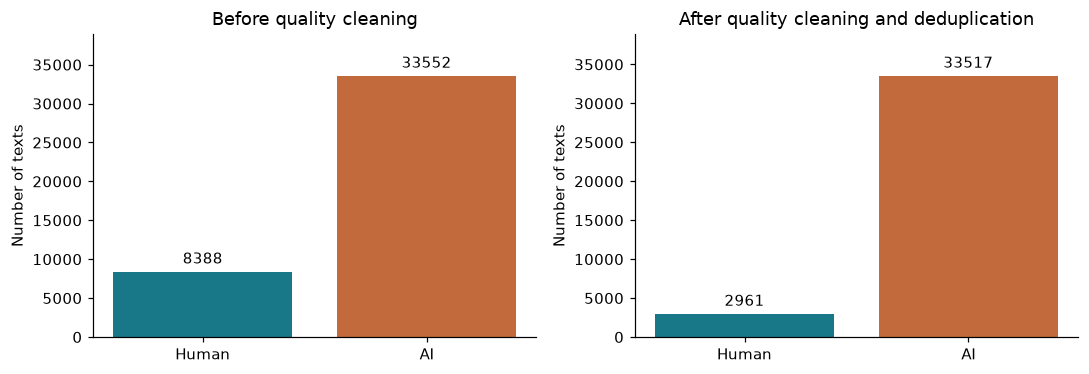

In [5]:
# ملاحظة الطالب: حذف التكرار وربط المصدر
# Union-find connects source families that share a normalized text.
# ملاحظة: قائمة ربط عائلات المصدر؛ ليست نموذج تعلم آلي.
parent = {g:g for g in valid['source_group'].unique()}
def find(g):
    while parent[g] != g:
        parent[g] = parent[parent[g]]
        g = parent[g]
    return g
# ملاحظة: إذا اشتركت عائلتان في نص مطبع أربطهما بمجموعة واحدة.
def union(a,b):
    a,b = find(a),find(b)
    if a != b:
        parent[max(a,b)] = min(a,b)
first_group = {}
for text, group in zip(valid['text_normalized'], valid['source_group']):
    if text in first_group:
        union(group, first_group[text])
    else:
        first_group[text] = group
valid['group_id'] = valid['source_group'].map(find)
def joined(values):
    return '|'.join(sorted(set(values)))
# ملاحظة: أجمع معلومات المصدر قبل حذف الصفوف المتكررة حتى لا أفقدها.
provenance = valid.groupby('text_key', sort=False).agg(
    generation_methods=('generation_method',joined), generators=('generator',joined),
    source_rows=('source_row',joined), occurrences=('source_row','size')).reset_index()
# ملاحظة: نسخة واحدة لكل نص كامل بعد توحيد Unicode والمسافات.
corpus = valid.drop_duplicates('text_key').drop(columns=['generation_method','generator','source_row'])
corpus = corpus.merge(provenance,on='text_key',validate='one_to_one').reset_index(drop=True)
corpus['text_id'] = corpus['text_key'].map(lambda s:hashlib.sha256(s.encode()).hexdigest())
assert corpus['text_id'].is_unique
assert corpus.groupby('text_normalized')['group_id'].nunique().max() == 1
class_counts = pd.DataFrame({
    'raw_text_slots': long['class_name'].value_counts(),
    'valid_nonconflicting_occurrences': valid['class_name'].value_counts(),
    'unique_exact_texts': corpus['class_name'].value_counts()}).reindex(LABELS).fillna(0).astype(int)
class_counts['unique_percent'] = (100*class_counts['unique_exact_texts']/len(corpus)).round(2)
display(class_counts)
save_table(class_counts,'phase1_class_distribution')
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax, col, title in zip(axes,['raw_text_slots','unique_exact_texts'],
                         ['Before quality cleaning','After quality cleaning and deduplication']):
    counts = class_counts[col]
    ax.bar(counts.index,counts.values,color=[COLORS[x] for x in LABELS])
    ax.set(title=title,ylabel='Number of texts')
    ax.bar_label(ax.containers[0],padding=3)
    ax.margins(y=0.16)
finish(fig,'phase1_class_distribution')


### ملاحظتي على خطوة حذف التكرار وربط المصدر

**ماذا فعلت؟** أحتفظ بنسخة واحدة من النص الكامل مع معلومات جميع مصادره، وأربط النص الأصلي بنسخه المولدة.

**كيف أقرأ الناتج؟** بقي 36,478 نصًا: 2,961 Human و33,517 AI. الرسم الأيسر قبل التنظيف والأيمن بعده؛ أعداد الفئتين غير متساوية.

**لماذا هذه الخطوة؟** Union-find تجمع عائلات المصدر التي تشترك في نص مطبع، حتى لا تتوزع نسخ البحث نفسه على مجموعات مختلفة.


### 1.5 | حجز البيانات مبكرًا لحماية التحليل اللاحق
هذه خطوة وقائية تنفيذًا لتنبيه منع التسرب في التعليمات، وليست تنفيذًا لهندسة الخصائص أو النمذجة.
نحجز نحو 70%/15%/15% **من مجموعات المصدر** ببذرة ثابتة. النسب على مستوى النصوص
قد تختلف قليلًا لأن أحجام المجموعات مختلفة. الرسوم والتحليل اللغوي في المرحلة الثانية
يستخدمان التدريب فقط؛ نحتفظ بالتحقق والاختبار دون استعراض نصوصهما أو مقاييسهما اللغوية.
لا تُستخدم طريقة التوليد أو اسم النموذج كمدخل لتصنيف النص في أي مرحلة لاحقة.


In [6]:
# ملاحظة الطالب: الحجز المبكر للبيانات
groups = np.array(sorted(corpus['group_id'].unique()))
# ملاحظة: تقليب ثابت لعائلات المصدر باستخدام البذرة المحددة.
np.random.default_rng(SEED).shuffle(groups)
n_train, n_val = int(.70*len(groups)), int(.15*len(groups))
assert min(n_train,n_val,len(groups)-n_train-n_val) > 0
split_map = {g:'train' for g in groups[:n_train]}
split_map.update({g:'validation' for g in groups[n_train:n_train+n_val]})
split_map.update({g:'test' for g in groups[n_train+n_val:]})
# ملاحظة: كل النصوص التابعة للمجموعة نفسها تحصل على القسم نفسه.
corpus['partition'] = corpus['group_id'].map(split_map)
# ملاحظة: فحص يمنع وجود المجموعة نفسها أو النص المطبع نفسه في أكثر من قسم.
assert corpus.groupby('group_id')['partition'].nunique().max() == 1
assert corpus.groupby('text_normalized')['partition'].nunique().max() == 1
assert corpus.groupby('partition')['label'].nunique().eq(2).all()
partition_counts = pd.crosstab(corpus['partition'],corpus['class_name']).reindex(
    index=['train','validation','test'],columns=LABELS,fill_value=0)
partition_counts['total'] = partition_counts.sum(axis=1)
partition_counts['percent_of_texts'] = (100*partition_counts['total']/len(corpus)).round(2)
display(partition_counts)
save_table(partition_counts,'phase1_partition_sizes')
corpus.drop(columns=['text_key','is_valid_string']).to_parquet(
    PROJECT/'data/processed/phase1_corpus.parquet',index=False)
audit = {'dataset_id':DATASET_ID,'revision':REVISION,'source_rows':len(wide),
         'raw_text_slots':len(long),'invalid_slots':len(invalid),'no_arabic_rows':len(no_arabic),
         'conflicting_rows':len(conflicts),'exact_duplicate_rows_removed':len(valid)-len(corpus),
         'unique_texts':len(corpus),'source_families_after_linking':len(groups)}
(TABLES/'phase1_audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
display(pd.Series(audit).to_frame('value'))


class_name,Human,AI,total,percent_of_texts
partition,,,,
train,2069,23508,25577,70.12
validation,445,4989,5434,14.90
test,447,5020,5467,14.99


,value
dataset_id,KFUPM-JRCAI/arabic-generated-abstracts
revision,584e43a346914a4cb1a51f9679f903284b65c36e
source_rows,8388
raw_text_slots,41940
invalid_slots,0
no_arabic_rows,4
conflicting_rows,117
exact_duplicate_rows_removed,5341
unique_texts,36478
source_families_after_linking,2991


### ملاحظتي على خطوة الحجز المبكر للبيانات

**ماذا فعلت؟** أحجز عائلات المصدر بنسبة تقريبية 70/15/15، وأحفظ خريطة تقسيم ثابتة.

**كيف أقرأ الناتج؟** النسبة تخص مجموعات المصدر وقد تختلف قليلًا عند عد النصوص. بيانات EDA تضم 25,577 نص تدريب.

**لماذا هذه الخطوة؟** حجزت الاختبار قبل التحليل اللغوي حتى لا أوجه قرارات المشروع باستخدامه. هذه وقاية مبكرة؛ لم أبدأ النمذجة.


## Phase 2 - Arabic Preprocessing & EDA
### 2.1 | تصميم المعالجة العربية - Task 2.1

نحتفظ بثلاث نسخ بالإضافة إلى النص الأصلي:

| Column | Purpose |
|---|---|
| `text_raw` | علامات الترقيم، حدود الجمل، التشكيل، والأسلوب الأصلي |
| `text_normalized` | NFKC، إزالة التشكيل والتطويل، أ/إ/آ/ٱ → ا، ى → ي، وحروف عربية فقط |
| `text_no_stopwords` | إزالة كلمات الوقف العربية من NLTK بعد تطبيع القائمة بالطريقة نفسها |
| `text_stemmed` | تجذير ISRI للكلمات المتبقية |

نبقي `ة` و`ء` و`ؤ` و`ئ` لأن دمجها قد يغير المعنى؛ ISRI يطبق قواعده داخل مرحلة التجذير.
إزالة الأرقام والحروف الأجنبية مقصودة للنسخة العربية المعالجة، وقد تفقد معلومات علمية؛
لذلك لا تُطبق على نسخة التحليل الأسلوبي الأصلية. ISRI تجذير جذري وقد يزيد دمج كلمات مختلفة،
ولذلك نعرض النسخة غير المجذرة أيضًا. لا نعيد تعريف كلمات الوقف اعتمادًا على الاختبار.


In [7]:
# ملاحظة الطالب: تنظيف العربية
# ملاحظة: قائمة كلمات وقف عربية قياسية من NLTK، وليست قائمة مأخوذة من الاختبار.
nltk_data_dir = PROJECT/'data/external/nltk_data'
assert nltk.download('stopwords', download_dir=str(nltk_data_dir), quiet=True), 'Stopword download failed'
nltk.data.path.insert(0,str(nltk_data_dir))
# ملاحظة: أطبق التطبيع نفسه على قائمة الوقف وعلى النصوص لضمان تطابق الكلمات.
AR_STOPWORDS = {w for s in stopwords.words('arabic') for w in normalize_arabic(s).split()}
(PROJECT/'data/external/arabic_stopwords_normalized.txt').write_text(
    '\n'.join(sorted(AR_STOPWORDS)),encoding='utf-8')
stemmer = ISRIStemmer()
@lru_cache(maxsize=100000)
# ملاحظة: أخزن جذور الكلمات المتكررة مؤقتًا لتقليل وقت التشغيل.
def stem_token(token):
    return stemmer.stem(token)
def remove_stopwords(text):
    return ' '.join(w for w in text.split() if w not in AR_STOPWORDS)
def stem_text(text):
    return ' '.join(stem_token(w) for w in text.split())

# Only the training partition is opened for phase-2 exploration.
# ملاحظة: هذا هو الجزء المستخدم في التحليل اللغوي: نصوص التدريب فقط.
eda = corpus.loc[corpus['partition'].eq('train')].copy().reset_index(drop=True)
eda['text_no_stopwords'] = eda['text_normalized'].map(remove_stopwords)
eda['text_stemmed'] = eda['text_no_stopwords'].map(stem_text)
empty_after_stopwords = eda['text_no_stopwords'].eq('')
print('Normalized stopwords:',len(AR_STOPWORDS))
print('Empty training texts after stopword removal:',int(empty_after_stopwords.sum()))
save_table(eda.loc[empty_after_stopwords,['text_id','class_name']], 'phase2_empty_after_stopwords',False)
# Do not silently drop them: EDA statistics remain linked to the original training corpus.
example = 'إِنَّ هٰذِهِ دِرَاسَةٌ عَنْ الذَّكَاءِ الاصْطِنَاعِيِّ، في عام 2026!'
print('Original:    ',example)
print('Normalized:  ',normalize_arabic(example))
print('No stopwords:',remove_stopwords(normalize_arabic(example)))
print('ISRI stems:  ',stem_text(remove_stopwords(normalize_arabic(example))))
examples = pd.concat([eda[eda['class_name'].eq(c)].head(2) for c in LABELS])
display(examples[['class_name','text_raw','text_normalized','text_no_stopwords','text_stemmed']])
save_table(examples[['class_name','text_raw','text_normalized','text_no_stopwords','text_stemmed']],
           'phase2_preprocessing_examples',False)

# Meaningful checks for token boundaries, normalization and empty input.
assert normalize_arabic('أَحْمَد إِلَى الْمَدْرَسَةِ') == 'احمد الي المدرسة'
assert normalize_arabic('علم،بحث AI 123') == 'علم بحث'
assert normalize_arabic(None) == ''
assert normalize_arabic('ة ء ؤ ئ') == 'ة ء ؤ ئ'
assert normalize_arabic(normalize_arabic(example)) == normalize_arabic(example)
assert remove_stopwords('في من علي') == ''
assert not eda['text_stemmed'].str.contains(r'[A-Za-z0-9]',regex=True).any()
print('Preprocessing checks passed.')


Normalized stopwords: 625
Empty training texts after stopword removal: 0
Original:     إِنَّ هٰذِهِ دِرَاسَةٌ عَنْ الذَّكَاءِ الاصْطِنَاعِيِّ، في عام 2026!
Normalized:   ان هذه دراسة عن الذكاء الاصطناعي في عام
No stopwords: دراسة الذكاء الاصطناعي عام
ISRI stems:   درس ذكء صطناع عام
Preprocessing checks passed.


,class_name,text_raw,text_normalized,text_no_stopwords,text_stemmed
0,Human,كثيرا ما ارتبطت المصادر التاريخية في الأندلس خ...,كثيرا ما ارتبطت المصادر التاريخية في الاندلس خ...,ارتبطت المصادر التاريخية الاندلس كتب التراجم و...,ربط صدر ارخ دلس كتب رجم هرس رمج وغر درس حية عل...
1,Human,يقوم المقال على اشكالية الضرائب الغير شرعية في...,يقوم المقال علي اشكالية الضرائب الغير شرعية في...,يقوم المقال اشكالية الضرائب الغير شرعية مختلف ...,يقم قال شكل ضرب غير شرع خلف رحل دول ربط وحد قي...
2069,AI,يتناول هذا البحث موضوع التعليم بين النساء الأن...,يتناول هذا البحث موضوع التعليم بين النساء الان...,يتناول البحث موضوع التعليم النساء الاندلسيات خ...,نول بحث وضع علم نسء دلس خلل درس صدر ارخ تعلق ر...
2070,AI,يتناول هذا البحث إشكالية الضرائب غير الشرعية ف...,يتناول هذا البحث اشكالية الضرائب غير الشرعية ف...,يتناول البحث اشكالية الضرائب الشرعية دولتي الم...,نول بحث شكل ضرب شرع دول ربط وحد اثر علق دول بر...


### ملاحظتي على خطوة تنظيف العربية

**ماذا فعلت؟** أنشئ نصًا مطبعًا، ثم نسخة بلا كلمات وقف، ثم نسخة مجذرة بـISRI، مع بقاء النص الأصلي.

**كيف أقرأ الناتج؟** أقارن المثال قبل كل خطوة وبعدها. assert يفحص صحة افتراضات محددة؛ ظهور Preprocessing checks passed يعني نجاح هذه الفحوص.

**لماذا هذه الخطوة؟** لا أستخدم النسخة التي حذفت منها العلامات لحساب الترقيم أو طول الجملة، لأن هذه المعلومات ستضيع.


### 2.2 | إحصاءات لغوية حسب الفئة - Task 2.2
نحسب عدد الكلمات، متوسط طول الكلمة بالحروف، متوسط طول الجملة بالكلمات، وTTR
على النص المطبع **قبل حذف كلمات الوقف والتجذير**. تقسيم الجمل بالترقيم تقريب عملي
قد يتأثر بالاختصارات والأرقام. TTR يتأثر بطول النص؛ نضيف TTR لأول 50 كلمة للنصوص
التي تتضمن 50 كلمة على الأقل، مع إظهار عدد النصوص المؤهلة.
نقيس الترقيم لكل 100 حرف من الأصل وكلمات الوقف لكل 100 كلمة، لتقليل أثر اختلاف الأطوال.
هذه مقاييس وصفية للمرحلة الثانية ولا ننشئ مصفوفة خصائص أو ندرب نموذجًا.


In [8]:
# ملاحظة الطالب: حساب الإحصاءات الوصفية
# ملاحظة: حدود الجمل تقريبية وتعتمد على الترقيم والأسطر الجديدة.
SENTENCE_BOUNDARY = re.compile(r'[.!?؟؛;\n]+')
PUNCTUATION = set('.,،;؛:!?؟"«»()[]{}…-–—')
# ملاحظة: هذه إحصاءات وصفية للنص، وليست مصفوفة خصائص تدريب في هذه المرحلة.
def linguistic_stats(row):
    raw, normalized = row['text_raw'], row['text_normalized']
    words = normalized.split()
    n = len(words)
    sentence_tokens = [normalize_arabic(s).split() for s in SENTENCE_BOUNDARY.split(raw)]
    sentence_lengths = [len(s) for s in sentence_tokens if s]
    return {
        'word_count':n, 'avg_word_length':sum(map(len,words))/n if n else np.nan,
        'sentence_count':len(sentence_lengths),
        'avg_sentence_length':float(np.mean(sentence_lengths)) if sentence_lengths else np.nan,
        'ttr':len(set(words))/n if n else np.nan,
        'ttr_first_50':len(set(words[:50]))/50 if n>=50 else np.nan,
        'function_words_per_100_words':100*sum(w in AR_STOPWORDS for w in words)/n if n else np.nan,
        'punctuation_per_100_chars':100*sum(c in PUNCTUATION for c in raw)/max(len(raw),1),
        'diacritics_per_100_chars':100*len(DIACRITICS.findall(raw))/max(len(raw),1),
        'retained_word_fraction':len(row['text_no_stopwords'].split())/n if n else np.nan}
stats = pd.DataFrame([linguistic_stats(r) for _,r in eda.iterrows()])
eda = pd.concat([eda,stats],axis=1)
METRICS = list(stats.columns)
# ملاحظة: أجمع الإحصاءات حسب الفئة دون الجمع بين Human وAI في متوسط واحد.
summary = eda.groupby('class_name')[METRICS].agg(['count','mean','median','std']).reindex(LABELS)
display(summary.round(4))
save_table(summary,'phase2_linguistic_summary')
display(eda.groupby('class_name')[['word_count','ttr','ttr_first_50']].mean().round(4))
method_summary = eda.groupby(['class_name','generation_methods'])[
    ['word_count','avg_sentence_length','ttr']].agg(['count','mean'])
save_table(method_summary,'phase2_by_generation_method')
print('Generation-method combinations are retained for human texts shared across methods.')


Generation-method combinations are retained for human texts shared across methods.


word_count                   ... retained_word_fraction                
                count      mean median  ...                   mean  median     std
class_name                              ...                                       
Human            2069  118.3900  109.0  ...                 0.7589  0.7625  0.0498
AI              23508  100.9678   99.0  ...                 0.7881  0.7901  0.0397

[2 rows x 40 columns]

,word_count,ttr,ttr_first_50
class_name,,,
AI,100.9678,0.7673,0.8564
Human,118.3900,0.7926,0.8829


### ملاحظتي على خطوة حساب الإحصاءات الوصفية

**ماذا فعلت؟** أحسب الطول وتنوع المفردات والكلمات الوظيفية والترقيم لكل نص تدريب، ثم ألخصها حسب الفئة.

**كيف أقرأ الناتج؟** count عدد النصوص المؤهلة، mean المتوسط، median الوسيط، std الانحراف المعياري. القيمة NaN في TTR لأول 50 كلمة تعني أن النص أقصر من 50 كلمة.

**لماذا هذه الخطوة؟** TTR = عدد الكلمات المختلفة ÷ إجمالي الكلمات. أضيف أول 50 كلمة لتقليل أثر اختلاف الأطوال، مع بقاء هذا مقياسًا وصفيًا.


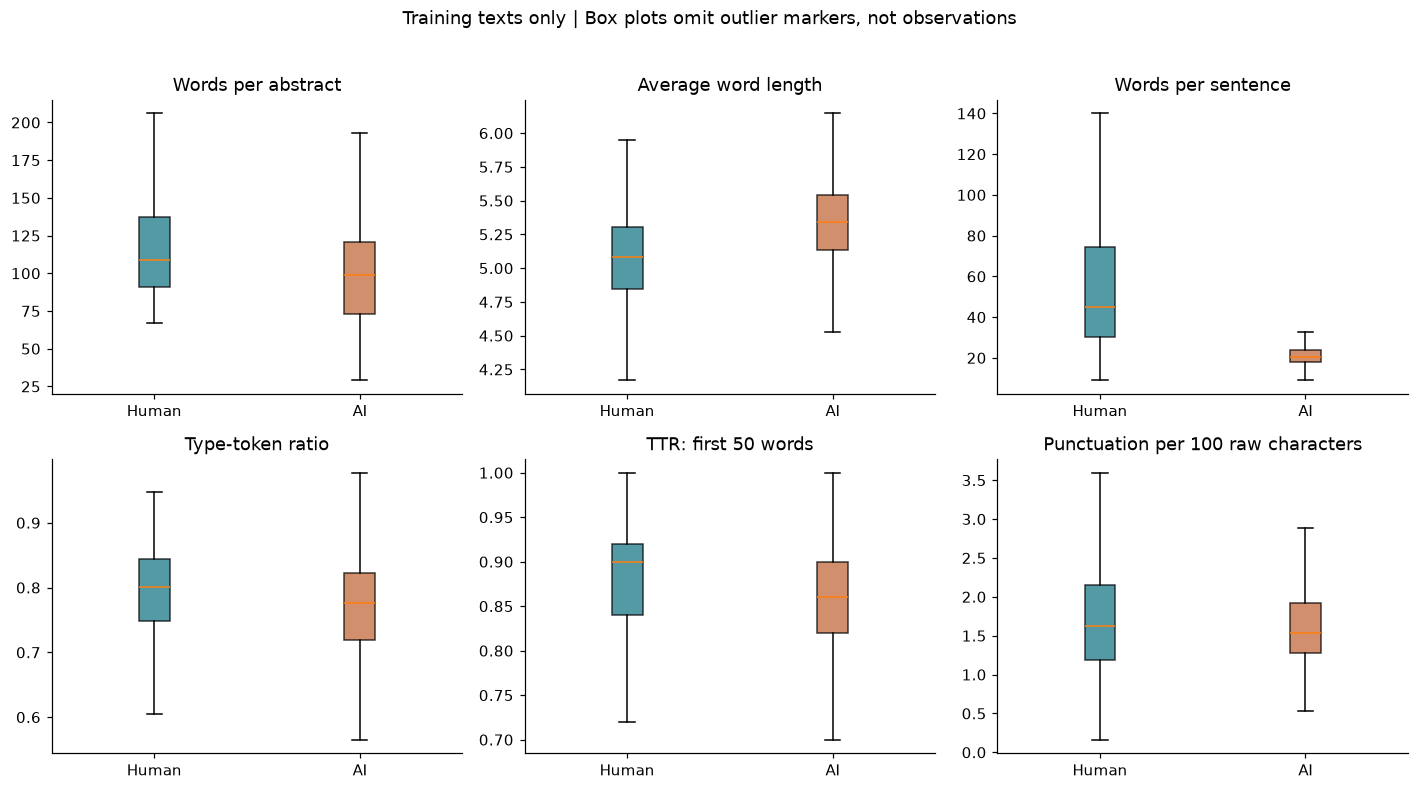

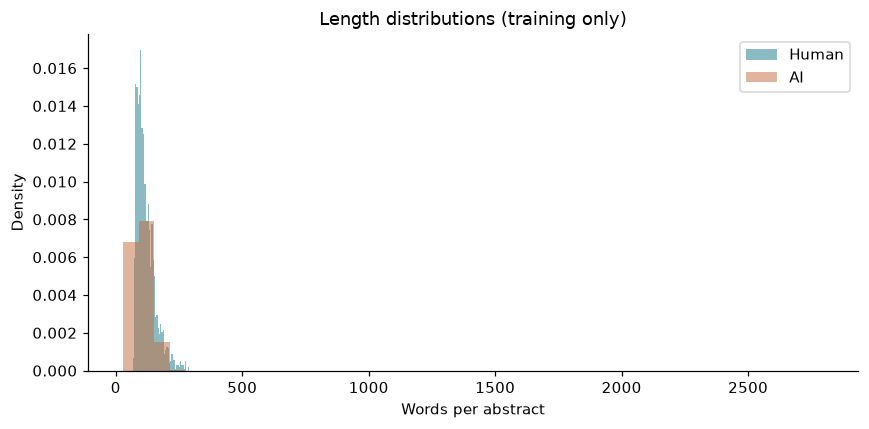

In [9]:
# ملاحظة الطالب: قراءة الرسوم الإحصائية
# ملاحظة: كل مربع يقارن مقياسًا واحدًا بين الفئتين.
plot_metrics = [('word_count','Words per abstract'),('avg_word_length','Average word length'),
                ('avg_sentence_length','Words per sentence'),('ttr','Type-token ratio'),
                ('ttr_first_50','TTR: first 50 words'),
                ('punctuation_per_100_chars','Punctuation per 100 raw characters')]
fig,axes = plt.subplots(2,3,figsize=(13,7))
for ax,(metric,title) in zip(axes.flat,plot_metrics):
    samples = [eda.loc[eda['class_name'].eq(c),metric].dropna() for c in LABELS]
    boxes = ax.boxplot(samples,patch_artist=True,showfliers=False)
    ax.set_xticks([1,2],LABELS)
    for patch,c in zip(boxes['boxes'],LABELS):
        patch.set_facecolor(COLORS[c]); patch.set_alpha(.75)
    ax.set_title(title)
fig.suptitle('Training texts only | Box plots omit outlier markers, not observations',y=1.02)
finish(fig,'phase2_linguistic_comparison')
fig,ax=plt.subplots(figsize=(8,4))
for c in LABELS:
    # ملاحظة: الكثافة النسبية تمنع أن يبدو التوزيع أكبر لمجرد أن عدد النصوص أكثر.
    ax.hist(eda.loc[eda['class_name'].eq(c),'word_count'],bins=45,density=True,
            alpha=.5,label=c,color=COLORS[c])
ax.set(xlabel='Words per abstract',ylabel='Density',title='Length distributions (training only)')
ax.legend(); finish(fig,'phase2_word_count_distribution')


### ملاحظتي على خطوة قراءة الرسوم الإحصائية

**ماذا فعلت؟** أعرض توزيع المقاييس بصناديق، وأعرض توزيع عدد الكلمات بكثافة نسبية لكل فئة.

**كيف أقرأ الناتج؟** الخط داخل الصندوق هو الوسيط، والصندوق يمثل النصف الأوسط من القيم. أخفي علامات القيم المتطرفة من الرسم فقط ولا أحذف بياناتها.

**لماذا هذه الخطوة؟** اختلاف توزيعين يصف نمطًا في البيانات، ولا يعني وحده أن لدي نموذج كشف دقيقًا.


### 2.3 | أكثر الكلمات والثنائيات والثلاثيات شيوعًا
نحسب التكرار **داخل كل نص** فلا ننشئ n-gram بين نهاية ملخص وبداية آخر.
الرسوم الأساسية تستخدم الكلمات قبل التجذير لسهولة التفسير. نحسب n-grams على النص المطبع
قبل إزالة كلمات الوقف حتى تبقى الكلمات المتجاورة متجاورة فعليًا، ثم نستبعد العبارات التي
تتكون بالكامل من كلمات وقف. نقارن التكرار لكل 10,000 موضع n-gram داخل الفئة بدل الأعداد
المطلقة، لأن عدد نصوص AI مختلف عن عدد النصوص البشرية.


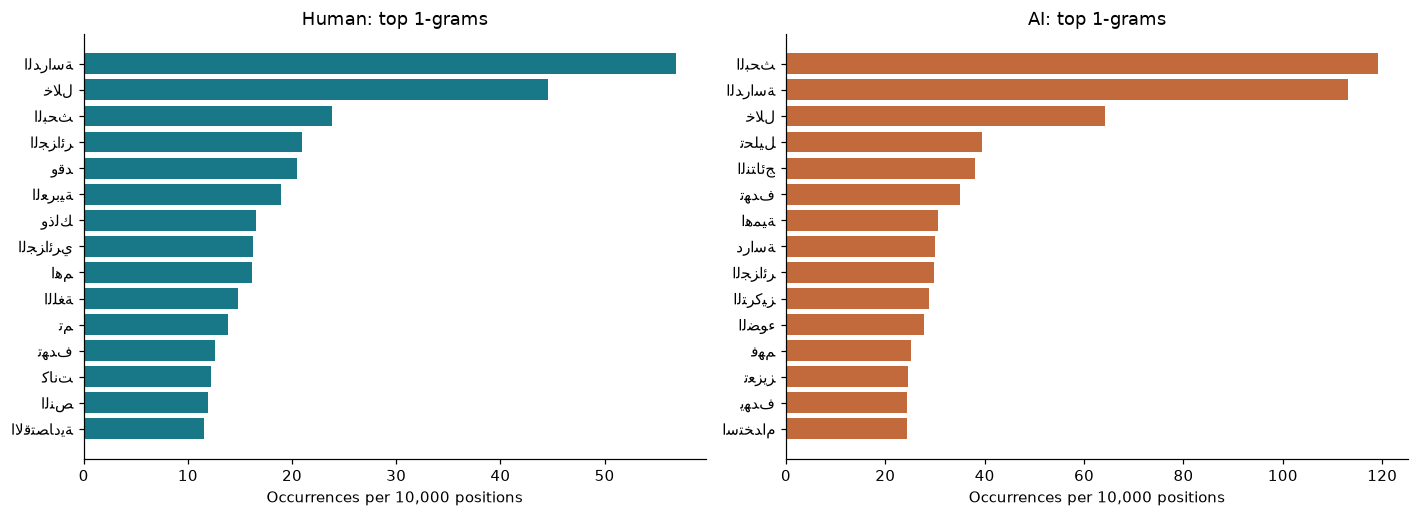

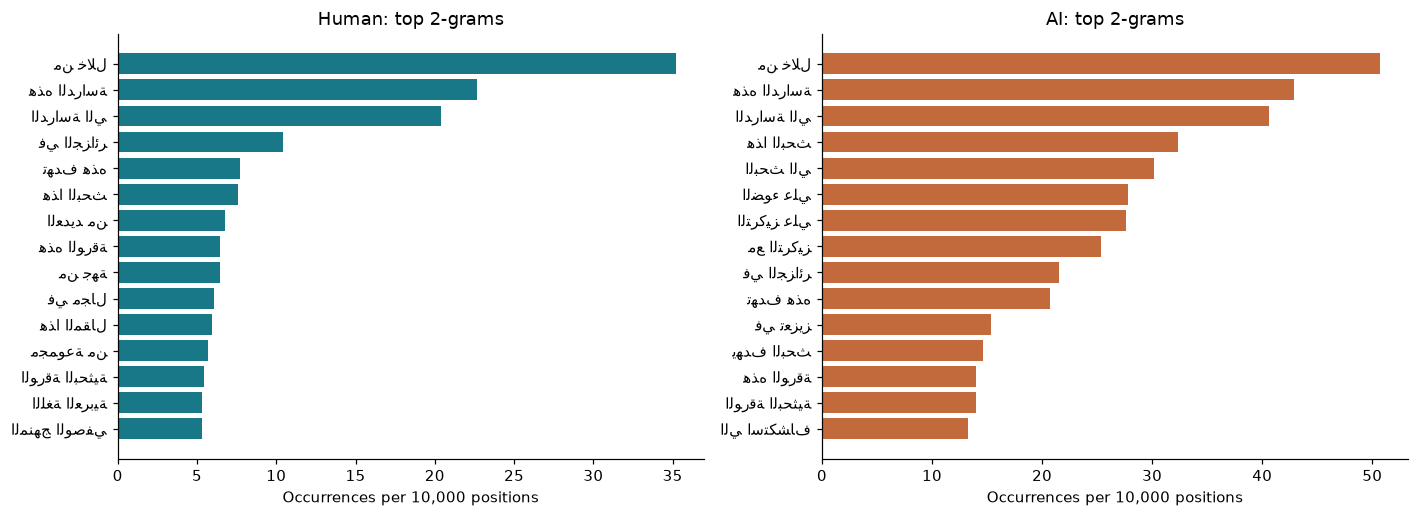

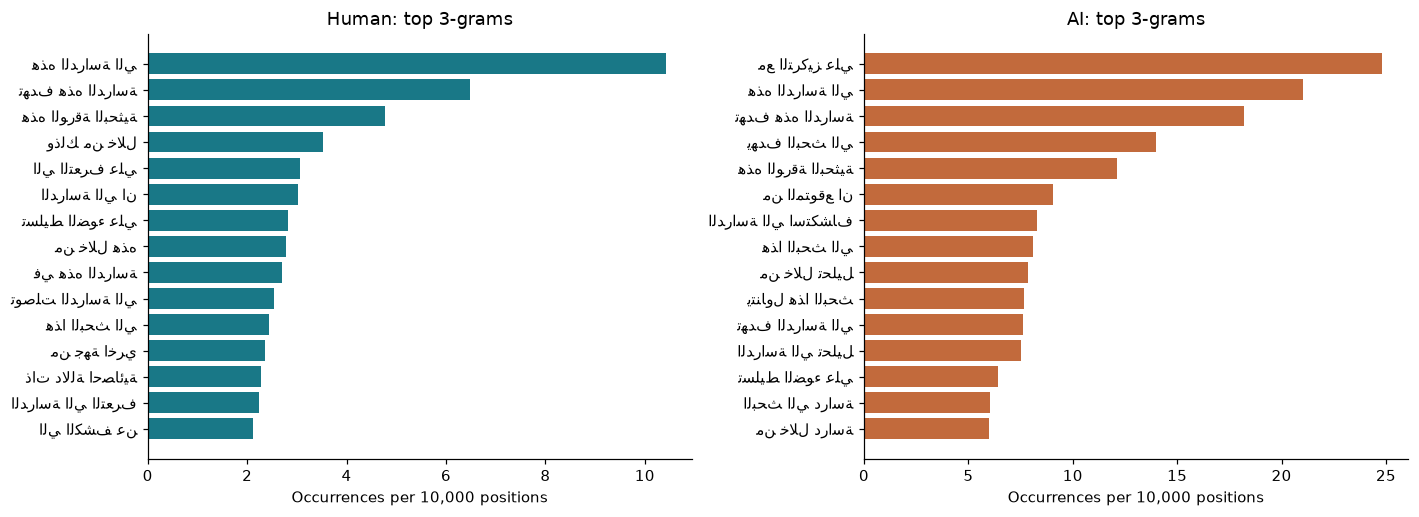

In [10]:
# ملاحظة الطالب: تحليل الكلمات والعبارات
# ملاحظة: أعيد العد داخل كل نص؛ لا أربط نهاية ملخص ببداية آخر.
def ngram_counts(texts,n=1):
    counts, opportunities = Counter(),0
    for text in texts:
        words = text.split()
        # ملاحظة: عدد المواضع الممكنة هو مقام معدل تكرار n-gram.
        opportunities += max(len(words)-n+1,0)
        for i in range(len(words)-n+1):
            gram=tuple(words[i:i+n])
            if not all(w in AR_STOPWORDS for w in gram):
                counts[' '.join(gram)]+=1
    return counts,opportunities

ngram_results = {}
# ملاحظة: أكرر التحليل للكلمة المفردة ثم العبارات من كلمتين وثلاث كلمات.
for n in [1,2,3]:
    fig,axes=plt.subplots(1,2,figsize=(13,4.8))
    for ax,c in zip(axes,LABELS):
        counts,total=ngram_counts(eda.loc[eda['class_name'].eq(c),'text_normalized'],n)
        ngram_results[c,n]=(counts,total)
        top=pd.DataFrame(counts.most_common(15),columns=['ngram','count'])
        top['per_10000_positions']=10000*top['count']/max(total,1)
        save_table(top,f'phase2_top_{n}grams_{c.lower()}',False)
        shown=top.iloc[::-1]
        ax.barh([ar(s) for s in shown['ngram']],shown['per_10000_positions'],color=COLORS[c])
        ax.set(title=f'{c}: top {n}-grams',xlabel='Occurrences per 10,000 positions')
    finish(fig,f'phase2_top_{n}grams')


### ملاحظتي على خطوة تحليل الكلمات والعبارات

**ماذا فعلت؟** أحسب الكلمات المفردة والثنائيات والثلاثيات داخل كل ملخص على حدة.

**كيف أقرأ الناتج؟** n=1 كلمة، وn=2 كلمتان متجاورتان، وn=3 ثلاث كلمات. المحور يعرض التكرار لكل 10,000 موضع داخل الفئة.

**لماذا هذه الخطوة؟** حسبت العبارات قبل حذف كلمات الوقف حتى لا أجعل كلمتين غير متجاورتين في الأصل تبدوان كعبارة متجاورة.


### 2.4 | سحابة كلمات مستقلة لكل فئة
تُعرض الكلمات العربية باتجاهها الصحيح عبر Arabic reshaper وBidi، باستخدام تكرار الكلمات
بعد حذف كلمات الوقف **وقبل ISRI** لقراءة مفهومة. حجم الكلمة نسبي داخل السحابة؛
لا تُفسر أحجام الكلمات بين السحابتين كاختبار إحصائي.


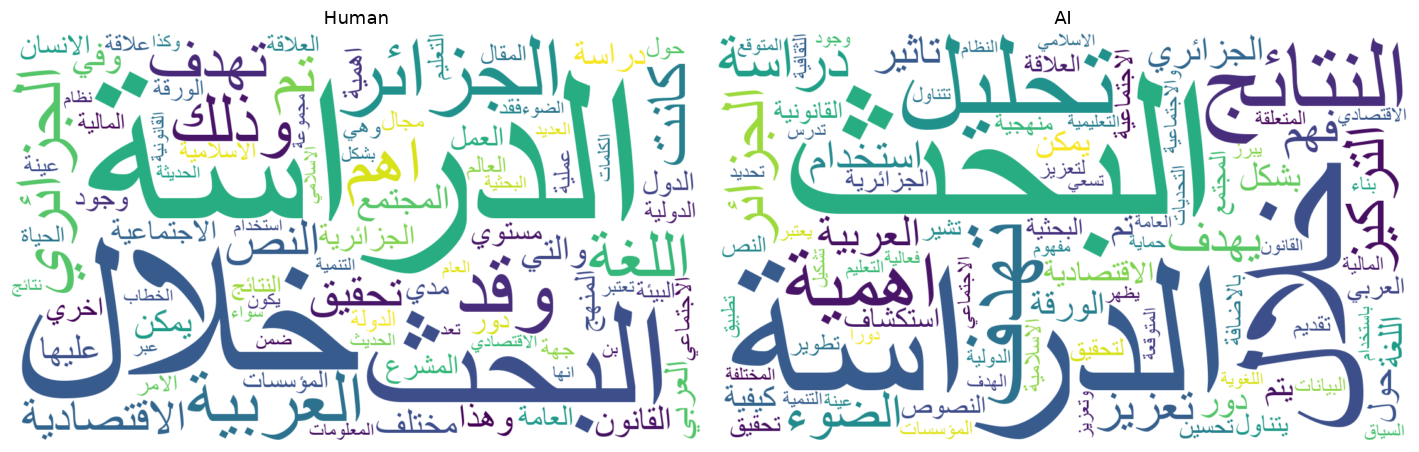

In [11]:
# ملاحظة الطالب: سحابات الكلمات
# ملاحظة: أبحث عن خط يدعم العربية في Colab أو Windows.
font_candidates=[
    Path('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf'),
    Path('/usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf'),
    Path('C:/Windows/Fonts/arial.ttf'),
    Path(font_manager.findfont('DejaVu Sans'))]
FONT = next((p for p in font_candidates if p.exists()),None)
assert FONT is not None,'An Arabic-compatible TrueType font is required.'
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,c in zip(axes,LABELS):
    counts=Counter(w for text in eda.loc[eda['class_name'].eq(c),'text_no_stopwords'] for w in text.split())
    assert counts,f'No tokens available for {c}'
    # Merge any display-equivalent tokens rather than overwriting their frequencies.
    # ملاحظة: تشكيل الحروف واتجاه العرض يخص الرسم فقط، ولا يغير النص المخزن.
    display_counts=Counter()
    for word,count in counts.items():
        display_counts[ar(word)]+=count
    cloud=WordCloud(width=1100,height=650,background_color='white',font_path=str(FONT),
                    collocations=False,max_words=90,random_state=SEED).generate_from_frequencies(display_counts)
    cloud.to_file(str(FIGURES/f'phase2_wordcloud_{c.lower()}.png'))
    ax.imshow(cloud,interpolation='bilinear'); ax.axis('off'); ax.set_title(c)
finish(fig,'phase2_wordcloud_comparison')


### ملاحظتي على خطوة سحابات الكلمات

**ماذا فعلت؟** أعرض الكلمات الأكثر تكرارًا في كل فئة بعد حذف كلمات الوقف وقبل التجذير، مع ضبط اتجاه العربية.

**كيف أقرأ الناتج؟** الكلمة الكبيرة أكثر تكرارًا داخل سحابتها. لا أقارن حجم كلمة في سحابة بحجمها في الأخرى على أنه فرق عددي مباشر.

**لماذا هذه الخطوة؟** استخدمت الكلمات غير المجذرة لأن جذور ISRI أقل وضوحًا في العرض البصري.


### 2.5 | الكلمات الوظيفية والترقيم والمصطلحات المحددة
قائمة كلمات الوقف هنا **مؤشر تقريبي** للكلمات الوظيفية وليست تحليلًا نحويًا.
نقيسها قبل حذفها، ونقيس الترقيم من الأصل. المصطلحات أدناه محددة مسبقًا كمثال لمفردات
الملخصات البحثية، ولا نختارها اعتمادًا على بيانات الاختبار.
التكرار المبني على كلمات مفصولة بمسافة لا يحل فصل اللواصق العربية مثل «وبحث» و«للدراسة».


,class_name,word,count,per_10000_words
0,Human,في,8717,355.869997
1,Human,من,7061,288.264088
2,Human,علي,4100,167.381782
3,Human,الي,3180,129.822943
4,Human,التي,2375,96.958959
5,Human,و,2103,85.854606
6,Human,ان,2102,85.813782
7,Human,هذه,1938,79.118510
8,Human,هذا,1510,61.645485
9,Human,عن,1365,55.725886


,class_name,sign,count,per_1000_chars
0,Human,،,14115,9.231898
1,Human,",",230,0.150431
2,Human,.,6670,4.362505
3,Human,؛,578,0.378040
4,Human,؟,169,0.110534
5,Human,!,2,0.001308
6,Human,«,34,0.022238
7,Human,»,33,0.021584
8,Human,:,890,0.582103
9,AI,،,113066,7.352363


,class_name,term,count,per_10000_words
0,Human,بحث,24,0.979796
1,Human,دراسة,243,9.920432
2,Human,نتائج,148,6.042074
3,Human,تحليل,136,5.552176
4,Human,منهج,52,2.122891
5,Human,بيانات,19,0.775672
6,AI,بحث,153,0.644604
7,AI,دراسة,7118,29.988835
8,AI,نتائج,1259,5.304291
9,AI,تحليل,9368,39.468307


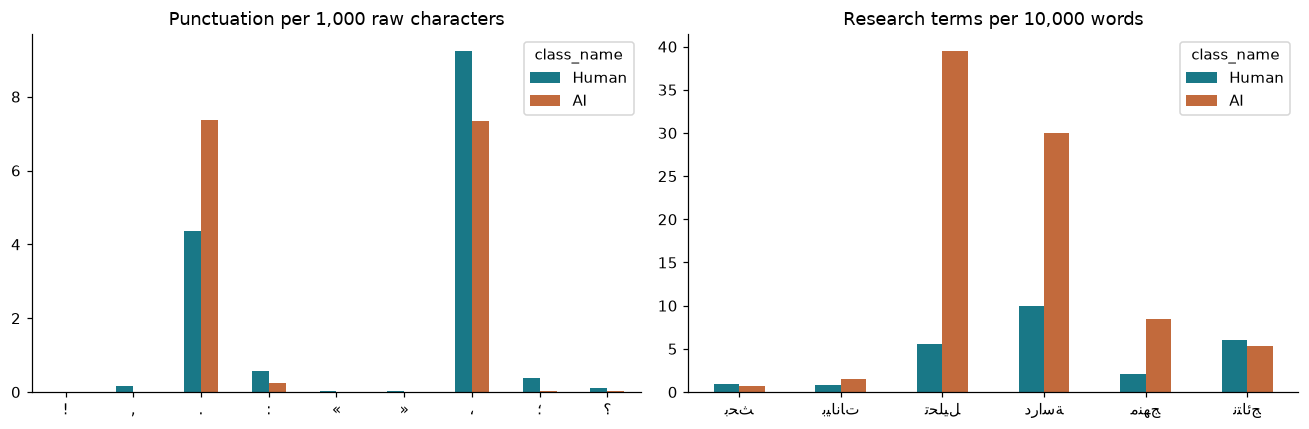

In [12]:
# ملاحظة الطالب: المقارنة المعجمية والأسلوبية
# ملاحظة: أمثلة محددة مسبقًا لمصطلحات بحثية؛ ليست كلمات مختارة من الاختبار.
terms = ['بحث','دراسة','نتائج','تحليل','منهج','بيانات']
function_rows, punctuation_rows, term_rows=[],[],[]
for c in LABELS:
    subset=eda.loc[eda['class_name'].eq(c)]
    tokens=Counter(w for text in subset['text_normalized'] for w in text.split())
    total=sum(tokens.values())
    function=Counter({w:n for w,n in tokens.items() if w in AR_STOPWORDS})
    for w,n in function.most_common(15):
        function_rows.append({'class_name':c,'word':w,'count':n,'per_10000_words':10000*n/max(total,1)})
    # ملاحظة: مقام الترقيم هو عدد الحروف الأصلية قبل إزالة العلامات.
    chars=sum(map(len,subset['text_raw']))
    for sign in ['،',',','.','؛','؟','!','«','»',':']:
        n=sum(t.count(sign) for t in subset['text_raw'])
        punctuation_rows.append({'class_name':c,'sign':sign,'count':n,'per_1000_chars':1000*n/max(chars,1)})
    for term in terms:
        w=normalize_arabic(term)
        term_rows.append({'class_name':c,'term':term,'count':tokens[w],
                          'per_10000_words':10000*tokens[w]/max(total,1)})
function_table=pd.DataFrame(function_rows)
punctuation_table=pd.DataFrame(punctuation_rows)
term_table=pd.DataFrame(term_rows)
for name,frame in [('function_words',function_table),('punctuation',punctuation_table),('research_terms',term_table)]:
    save_table(frame,'phase2_'+name,False); display(frame)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,frame,key,value,title in [
    (axes[0],punctuation_table,'sign','per_1000_chars','Punctuation per 1,000 raw characters'),
    (axes[1],term_table,'term','per_10000_words','Research terms per 10,000 words')]:
    # ملاحظة: أرتب الجدول إلى عمود لكل فئة لتسهيل الرسم والمقارنة.
    pivot=frame.pivot(index=key,columns='class_name',values=value).reindex(columns=LABELS)
    pivot.index=[ar(x) for x in pivot.index]
    pivot.plot.bar(ax=ax,color=[COLORS[c] for c in LABELS],rot=0)
    ax.set(title=title,xlabel='')
finish(fig,'phase2_lexical_comparison')


### ملاحظتي على خطوة المقارنة المعجمية والأسلوبية

**ماذا فعلت؟** أقارن كلمات الوقف بوصفها مؤشرًا للكلمات الوظيفية، وأقارن علامات الترقيم ومصطلحات بحثية محددة.

**كيف أقرأ الناتج؟** تكرار المصطلحات والكلمات لكل 10,000 كلمة، والترقيم لكل 1,000 حرف أصلي. هذه وحدات مختلفة، لذلك أقرأ عنوان كل محور.

**لماذا هذه الخطوة؟** التكرار النسبي يجعل المقارنة أوضح رغم تفاوت عدد نصوص Human وAI. القائمة ليست تحليلًا نحويًا كاملًا.


### 2.6 | تفسير النتائج تلقائيًا وحفظ المخرجات
الملخص التالي يصف الفروق الفعلية المحسوبة على التدريب فقط. الفروق وصفية وليست دليلًا
سببيًا أو اختبارًا لدقة الكشف. موضوعات النصوص وطريقة التوليد واسم النموذج وطول النص
قد تؤثر على المقارنات، والنصوص التابعة للبحث الواحد مترابطة.
البيانات ملخصات بحثية عربية، لذلك لا نعمم النتائج على جميع أنواع النصوص العربية.


In [13]:
# ملاحظة الطالب: تفسير النتائج وحفظها
# ملاحظة: أستخرج المتوسطات الفعلية لكتابة التفسير، دون إدخال أرقام يدويًا.
means=eda.groupby('class_name')[METRICS].mean().reindex(LABELS)
observations=[]
for metric in ['word_count','avg_word_length','avg_sentence_length','ttr','ttr_first_50',
               'function_words_per_100_words','punctuation_per_100_chars']:
    h,a=means.loc['Human',metric],means.loc['AI',metric]
    direction='higher' if a>h else ('lower' if a<h else 'equal')
    observations.append(f'- {metric}: Human = {h:.4f}; AI = {a:.4f}; AI is {direction} on average.')
report='\n'.join([
    '# Phase 1 and Phase 2 - Computed findings',
    f'Dataset: {DATASET_ID}; revision: {REVISION}.',
    f'Source rows: {len(wide):,}; raw text slots: {len(long):,}; unique usable texts: {len(corpus):,}.',
    f'Invalid slots: {len(invalid):,}; no-Arabic rows: {len(no_arabic):,}; contradictory-label rows: {len(conflicts):,}.',
    f'Exact duplicate occurrences removed: {len(valid)-len(corpus):,}.',
    f'EDA training texts: {len(eda):,}. Validation and test were reserved before linguistic exploration.',
    '## Descriptive class differences',*observations,
    '## Interpretation and limitations',
    '- Class sizes are unequal; frequency plots use within-class normalized rates.',
    '- Raw text is retained; punctuation and sentence statistics precede destructive cleaning.',
    '- TTR depends on length; first-50-token TTR is reported with eligible counts.',
    '- Repeated human abstracts are deduplicated; all related variants share a source group.',
    '- Normalization collisions stay in one group; ISRI may cause further collisions that must be audited before future modeling.',
    '- Grouping covers shared originals and normalized duplicates, not undetected semantic near-duplicates.',
    '- Punctuation-based sentence segmentation and whitespace tokenization are approximate.',
    '- ISRI is stemming, not lemmatization; stopwords approximate function words.',
    '- No significance tests or classifier-performance claims are made.',
    '- This corpus contains research abstracts; domain and generation-method confounding remain.',
    '- No models, feature-selection procedures or final test evaluation were run.'
])
display(Markdown(report))
(PROJECT/'reports/phase1_phase2_findings.md').write_text(report,encoding='utf-8')
# ملاحظة: أحفظ بيانات التدريب المعالجة منفصلة عن الأصل وخريطة التقسيم.
eda.to_parquet(PROJECT/'data/processed/phase2_training.parquet',index=False)
eda.to_csv(PROJECT/'data/processed/phase2_training.csv',index=False,encoding='utf-8-sig')
corpus[['text_id','group_id','partition','label','class_name','generation_methods','generators']].to_csv(
    PROJECT/'data/processed/partition_manifest.csv',index=False,encoding='utf-8-sig')
# ملاحظة: هذه إصدارات البيئة وقت التشغيل، وتفيد في تكرار العمل لاحقًا.
packages=['datasets','nltk','pandas','numpy','matplotlib','wordcloud','arabic-reshaper','python-bidi','pyarrow']
environment={p:version(p) for p in packages}
(PROJECT/'requirements-tested.txt').write_text('\n'.join(f'{p}=={v}' for p,v in environment.items())+'\n',encoding='utf-8')
(PROJECT/'docs/run_metadata.json').write_text(json.dumps(
    {'python':sys.version,'seed':SEED,'dataset_revision':REVISION,'packages':environment},indent=2),encoding='utf-8')
print('Saved outputs to:',PROJECT)
print('Figures:',len(list(FIGURES.glob('*.png'))),'| Tables:',len(list(TABLES.glob('*.csv'))))
assert eda['partition'].eq('train').all()
assert eda['text_id'].is_unique
assert not eda['text_normalized'].eq('').any()
assert corpus.groupby('group_id')['partition'].nunique().max()==1
print('Final integrity checks passed.')


Saved outputs to: C:\Users\omran\AppData\Local\Temp\m822-run\MSIS822_Arabic_AI_Phases_1_2
Figures: 10 | Tables: 20
Final integrity checks passed.


# Phase 1 and Phase 2 - Computed findings
Dataset: KFUPM-JRCAI/arabic-generated-abstracts; revision: 584e43a346914a4cb1a51f9679f903284b65c36e.
Source rows: 8,388; raw text slots: 41,940; unique usable texts: 36,478.
Invalid slots: 0; no-Arabic rows: 4; contradictory-label rows: 117.
Exact duplicate occurrences removed: 5,341.
EDA training texts: 25,577. Validation and test were reserved before linguistic exploration.
## Descriptive class differences
- word_count: Human = 118.3900; AI = 100.9678; AI is lower on average.
- avg_word_length: Human = 5.0744; AI = 5.3333; AI is higher on average.
- avg_sentence_length: Human = 54.8423; AI = 21.1921; AI is lower on average.
- ttr: Human = 0.7926; AI = 0.7673; AI is lower on average.
- ttr_first_50: Human = 0.8829; AI = 0.8564; AI is lower on average.
- function_words_per_100_words: Human = 24.1054; AI = 21.1880; AI is lower on average.
- punctuation_per_100_chars: Human = 1.7413; AI = 1.6526; AI is lower on average.
## Interpretation and limitations
- Class sizes are unequal; frequency plots use within-class normalized rates.
- Raw text is retained; punctuation and sentence statistics precede destructive cleaning.
- TTR depends on length; first-50-token TTR is reported with eligible counts.
- Repeated human abstracts are deduplicated; all related variants share a source group.
- Normalization collisions stay in one group; ISRI may cause further collisions that must be audited before future modeling.
- Grouping covers shared originals and normalized duplicates, not undetected semantic near-duplicates.
- Punctuation-based sentence segmentation and whitespace tokenization are approximate.
- ISRI is stemming, not lemmatization; stopwords approximate function words.
- No significance tests or classifier-performance claims are made.
- This corpus contains research abstracts; domain and generation-method confounding remain.
- No models, feature-selection procedures or final test evaluation were run.

### ملاحظتي على خطوة تفسير النتائج وحفظها

**ماذا فعلت؟** أكتب ملخصًا آليًا للأرقام الفعلية وأحفظ الجداول والرسوم والبيانات المعالجة ومعلومات البيئة.

**كيف أقرأ الناتج؟** متوسط الكلمات Human نحو 118.39 وAI نحو 100.97. وفي طول الجملة نحو 54.84 مقابل 21.19، وفق التقسيم التقريبي بالترقيم.

**لماذا هذه الخطوة؟** أفسر الأرقام ضمن ملخصات هذا المصدر فقط. لم أحسب accuracy أو F1 لأن تدريب النماذج مرحلة لاحقة.


## حفظ العمل وعرضه

الدفتر المعتمد موجود في `notebooks/MSIS822_Phase1_Phase2_Arabic_AI.ipynb`.
أفتح نسخة GitHub من زر **Open in Colab** في README عندما أحتاج أحدث نسخة من الملاحظات.
أجد التقرير في `reports/phase1_phase2_findings.md`، والرسوم في `reports/figures/`،
والجداول في `reports/tables/`.

خلية ZIP التالية اختيارية لتجميع نتائج جلسة التشغيل. أما ملفات جلسة Colab نفسها فهي مؤقتة؛
أحفظ ما أحتاجه قبل إنهاء الجلسة. قائمة التسليم وشرح الملفات موجودان في `docs/`.


In [14]:
# ملاحظة الطالب: تجميع ملفات النتائج
# Lightweight results package: figures, tables, report and reproducibility metadata.
# ملاحظة: حزمة النتائج تضم الملفات الصغيرة اللازمة للمراجعة، دون البيانات الكبيرة.
bundle=PROJECT/'submission_results'
bundle.mkdir(exist_ok=True)
for folder in ['reports','docs']:
    shutil.copytree(PROJECT/folder,bundle/folder,dirs_exist_ok=True)
shutil.copy2(PROJECT/'requirements-tested.txt',bundle/'requirements-tested.txt')
archive=shutil.make_archive(str(PROJECT/'MSIS822_Phases_1_2_results'),'zip',bundle)
print('Results ZIP:',archive)
# To download in Colab, uncomment the next two lines:
# from google.colab import files
# files.download(archive)


Results ZIP: C:\Users\omran\AppData\Local\Temp\m822-run\MSIS822_Arabic_AI_Phases_1_2\MSIS822_Phases_1_2_results.zip


### ملاحظتي على خطوة تجميع ملفات النتائج

**ماذا فعلت؟** أجمع التقرير والجداول والرسوم ومعلومات إعادة التشغيل في ZIP خفيف.

**كيف أقرأ الناتج؟** هذه الحزمة لا تشمل البيانات الخام أو الكاش ولا تنزل تلقائيًا؛ سطرا files.download اختياريان للتنزيل من Colab.

**لماذا هذه الخطوة؟** الملفات داخل جلسة Colab مؤقتة. الدفتر محفوظ في GitHub، والنتائج المهمة موجودة في reports/.


## مراجعة ما أنجزناه

| Requirement | Location |
|---|---|
| 1.1 Repository organization | Project folders + GitHub submission instructions |
| 1.2 Hugging Face `datasets` acquisition | Section 1.2 |
| 1.3 Schema, class balance, missing values, duplicates, inconsistencies | Sections 1.2-1.5 |
| 2.1 Arabic normalization, diacritics, standard stopwords, ISRI | Section 2.1 |
| 2.2 Linguistic statistics, word clouds, n-grams, lexical analysis | Sections 2.2-2.6 |

**لشرح الحل:** بدأنا بفهم الأعمدة، وحولناها إلى نص وتصنيف، ثم عزلنا القيم غير الصالحة
والتصنيفات المتعارضة وحذفنا التكرار. احتفظنا بعائلات المصدر معًا وحجزنا البيانات مبكرًا.
بعد ذلك أنشأنا نسخًا عربية معالجة، وقارنا التدريب البشري والمولد بإحصاءات ورسوم ذات تكرار نسبي.
بقي النص الأصلي محفوظًا لقياس الأسلوب. التحليل هنا وصفي؛ لا يمكن استنتاج دقة كشف قبل مراحل النمذجة.


## مصطلحات أحتاج أن أعرفها

| المصطلح | معناه في المشروع |
|---|---|
| Dataset | مجموعة البيانات التي حملتها من المصدر |
| Source row | صف بحث أصلي قد يضم خمسة نصوص |
| Label | الفئة: بشري 0 أو مولد 1 |
| Generation method | طريقة إنتاج النص، مثل التوليد من العنوان |
| Missing / blank | قيمة ناقصة / سلسلة نصية فارغة |
| Duplicate | نسخة مكررة من النص حسب قاعدة المقارنة المحددة |
| Normalization | توحيد شكل الكتابة، مثل أ وإ إلى ا |
| Stopwords | كلمات شائعة مثل في ومن نزيلها من نسخة معالجة |
| ISRI stemming | تحويل الكلمة إلى جذر تقريبي |
| TTR | عدد الكلمات المختلفة مقسومًا على إجمالي الكلمات |
| N-gram | كلمة أو سلسلة كلمات متجاورة |
| Data leakage | وصول معلومات من الاختبار إلى قرارات التدريب أو الاختيار |
| Group ID | عائلة النص الأصلي ونسخه المرتبطة |
| Assert | فحص برمجي يتوقف إذا لم يتحقق الشرط |
| Parquet / CSV | صيغتان لحفظ الجداول؛ CSV يسهل فتحه في Excel |
| Seed / revision | بذرة عشوائية ثابتة / نسخة ثابتة من البيانات |

## ماذا يأتي بعد المرحلتين؟

أبدأ المرحلة الثالثة لاحقًا من `data/processed/phase1_corpus.parquet` وخريطة التقسيم،
وأراجع تصادم النصوص بعد المعالجة قبل أي نمذجة. ملفات 03 و04 و05 في notebooks هي خطط
مستقبلية تحتوي على نصوص توضيحية فقط. لا توجد حاليًا نماذج مدربة أو نتائج دقة تصنيف.
